# Notebook to create Figure 2

In [1]:
packages <- c("ade4", "ggplot2", "gridExtra", "cluster", "dplyr", "glue")

for (pkg in packages) {
  if (!requireNamespace(pkg, quietly = TRUE)) {
    message(glue::glue("Installation du package : {pkg}"))
    install.packages(pkg)
  } else {
    message(glue::glue("Already installed package: {pkg}"))
  }
  library(pkg, character.only = TRUE)
}

library(glue)

Already installed package: ade4

Already installed package: ggplot2

Already installed package: gridExtra

Already installed package: cluster

Already installed package: dplyr


Attaching package: ‘dplyr’


The following object is masked from ‘package:gridExtra’:

    combine


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Already installed package: glue



In [2]:
# Paths to representation files
path <- glue("../../Data/Embeddings/")
dataset_name <- 'bacteria_1'

dnaberts_name <- glue('{path}{dataset_name}_dnaberts_embedding.csv')
dnabert2_name <- glue('{path}{dataset_name}_dnabert2_embedding.csv')
hyenadna_name <- glue('{path}{dataset_name}_hyenadna_embedding.csv')
dna2vec_name <- glue('{path}{dataset_name}_dna2vec_embedding.csv')
tnf_name <- glue('{path}{dataset_name}_tnf_embedding.csv')

In [3]:
species_label_dict <- c(
  "Streptomyces_sp._B-S-A12" = "Streptomyces luteolus",
  "Arthrobacter_sp._PGP41" = "Arthrobacter sp.",
  "Streptomyces_sp._A10_2020_" = "Streptomyces sp.",
  "Deinococcus_piscis" = "Deinococcus sp.",
  "Enterobacter_sp._LU1" = "Enterobacter sp.",
  "Rhizobium_sp._BK275" = "Rhizobium sp.",
  "Pseudaminobacter_soli" = "Pseudaminobacter sp.",
  "Candidatus_Microthrix_sp._UBA3522" = "Ca. Neomicrothrix sp.",
  "Wolbachia_endosymbiont_of_Ctenocephalides_felis_wCfeT" = "Wolbachia sp.",
  "Salinibacterium_sp._NSLL35" = "Salinibacterium sp."
)

if(dataset_name == 'bacteria_1'){
  palette <- c(
      "Enterobacter sp." = "#11aeb4", 
      "Ca. Neomicrothrix sp." = "#8214a0", 
      "Arthrobacter sp." = "#1800ad", 
      "Rhizobium sp." = "#9abc1d", 
      "Wolbachia sp." = "#aa0a3c", 
      "Streptomyces sp." = "#017a40", 
      "Salinibacterium sp." = "#fa7850", 
      "Pseudaminobacter sp." = "#000000", 
      "Streptomyces luteolus" = "#ffcc00", 
      "Deinococcus sp." = "#fa78fa")
}

## 1. Function to calculate representation principle components and plot them

In [4]:
create_pca <- function(data_frame, my_palette, plot=TRUE){
  species <- data_frame[,2]
  predictors <- data_frame[,3:ncol(data_frame)]

  pca_proj <- dudi.pca(predictors, scannf = FALSE, nf = 2)
  dat_pca_proj <- cbind(species, pca_proj$li)
  colnames(dat_pca_proj) <- c('species', 'PC1', 'PC2')

  dat_pca_proj$species_new <- species_label_dict[dat_pca_proj$species]
  dat_pca_proj$species_new <- factor(dat_pca_proj$species_new)

  if (plot == TRUE){
    print(
      ggplot(dat_pca_proj, aes(x=PC1, y=PC2, col = species_new)) + 
        geom_point(size = 3) +
        theme_minimal() +
        theme(legend.position = "right") +
        scale_color_manual(values = my_palette)
    )
  }
  return(dat_pca_proj)
}

## 2. DNABERT-S

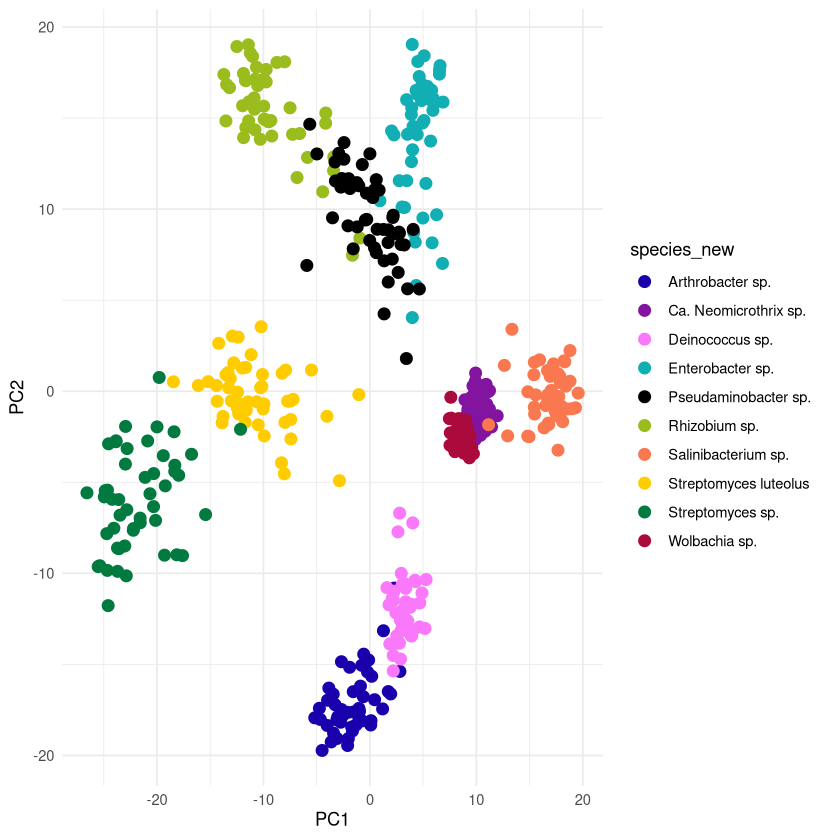

In [5]:
data_dnaberts <- read.table(dnaberts_name, header = F, sep=',')
dat_pca_proj_dnaberts <- create_pca(data_dnaberts, palette)
dat_pca_proj_dnaberts$PC1 <- dat_pca_proj_dnaberts$PC1 * -1
dat_pca_proj_dnaberts$PCA <- "DNABERT-S"

## 3. HyenaDNA

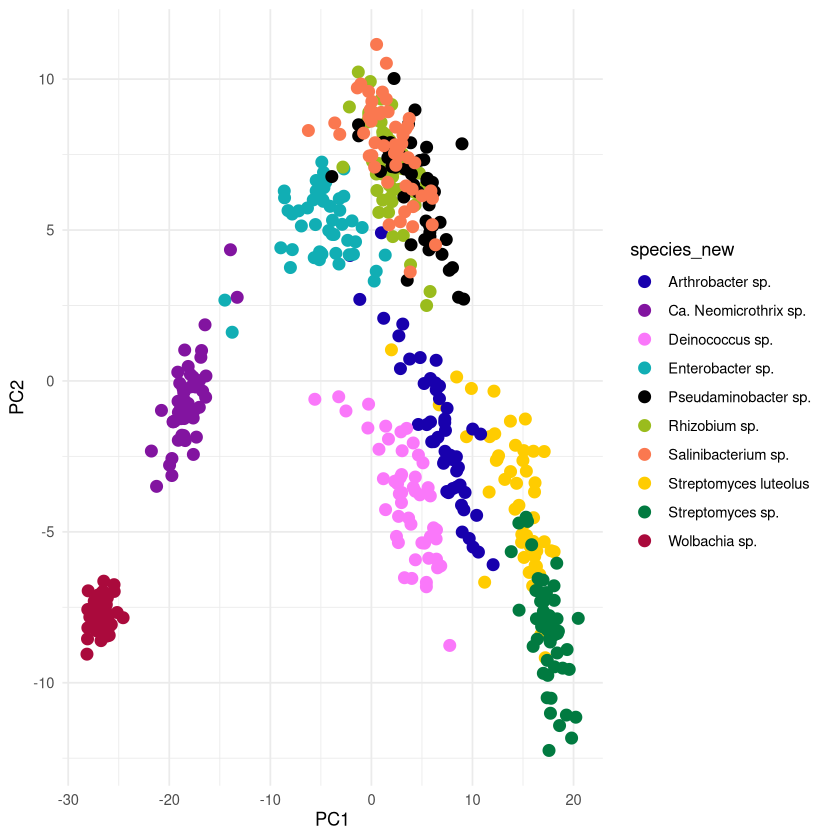

In [6]:
data_hyena <- read.table(hyenadna_name, header = F, sep=',')
dat_pca_proj_hyena <- create_pca(data_hyena, palette)
dat_pca_proj_hyena$PCA <- "HyenaDNA"

## 4. dna2vec

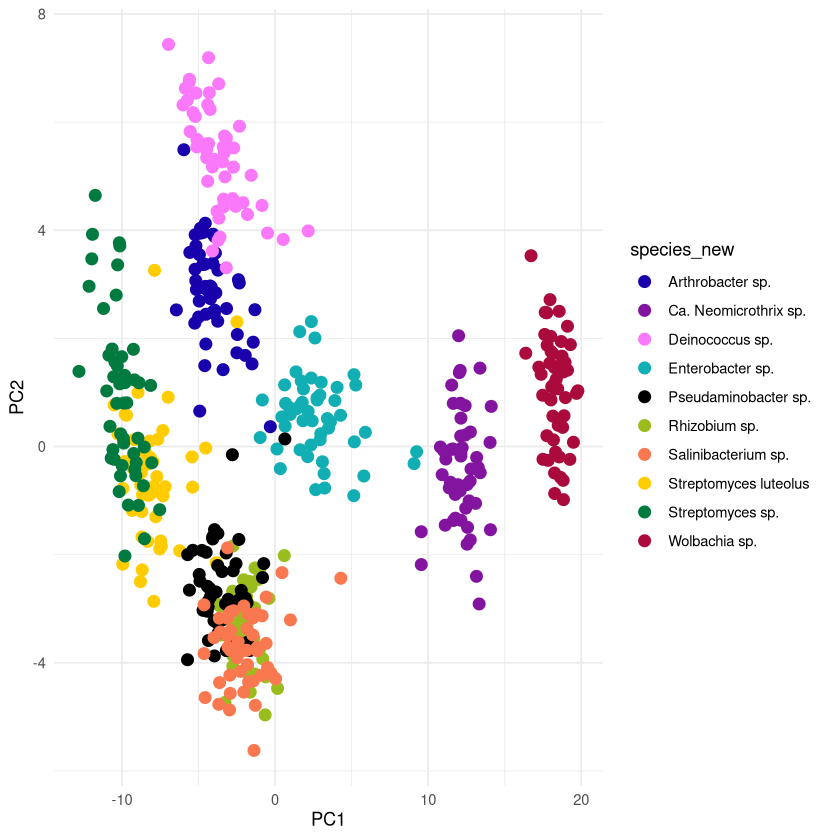

In [7]:
data_dna2vec <- read.table(dna2vec_name, header = F, sep=',')
dat_pca_proj_dna2vec <- create_pca(data_dna2vec, palette)
dat_pca_proj_dna2vec$PC1 <- dat_pca_proj_dna2vec$PC1 * -1
dat_pca_proj_dna2vec$PC2 <- dat_pca_proj_dna2vec$PC2 * -1
dat_pca_proj_dna2vec$PCA <- "dna2vec"

## 5. DNABERT-2

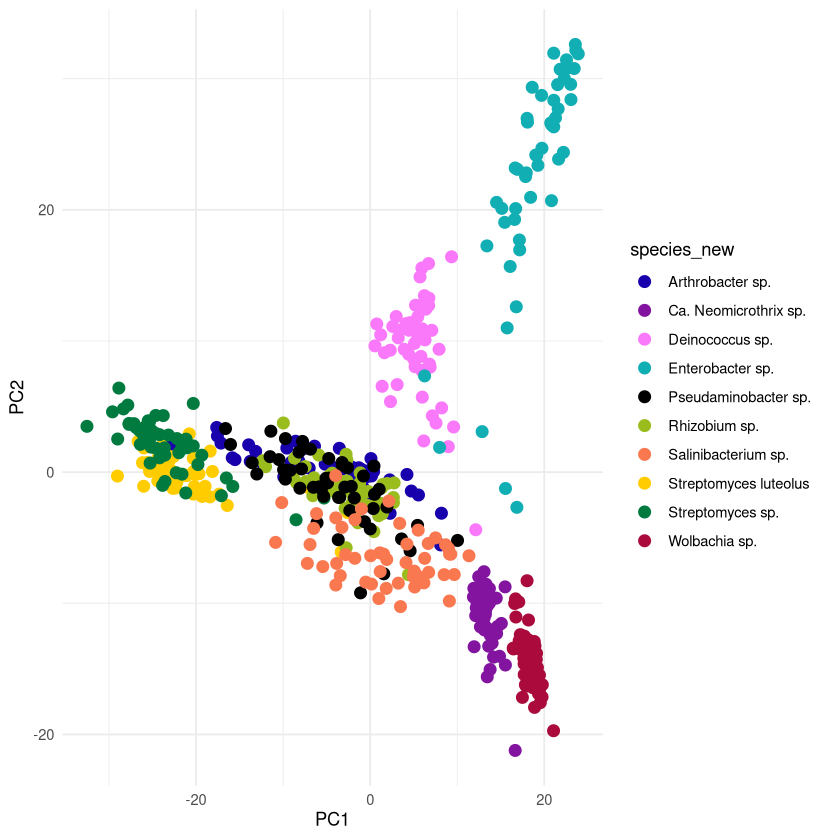

In [8]:
data_dnabert2 <- read.table(dnabert2_name, header = F, sep=',')
dat_pca_proj_dnabert2 <- create_pca(data_dnabert2, palette)
dat_pca_proj_dnabert2$PC1 <- dat_pca_proj_dnabert2$PC1 * -1
dat_pca_proj_dnabert2$PCA <- "DNABERT-2"

## 6. TNF

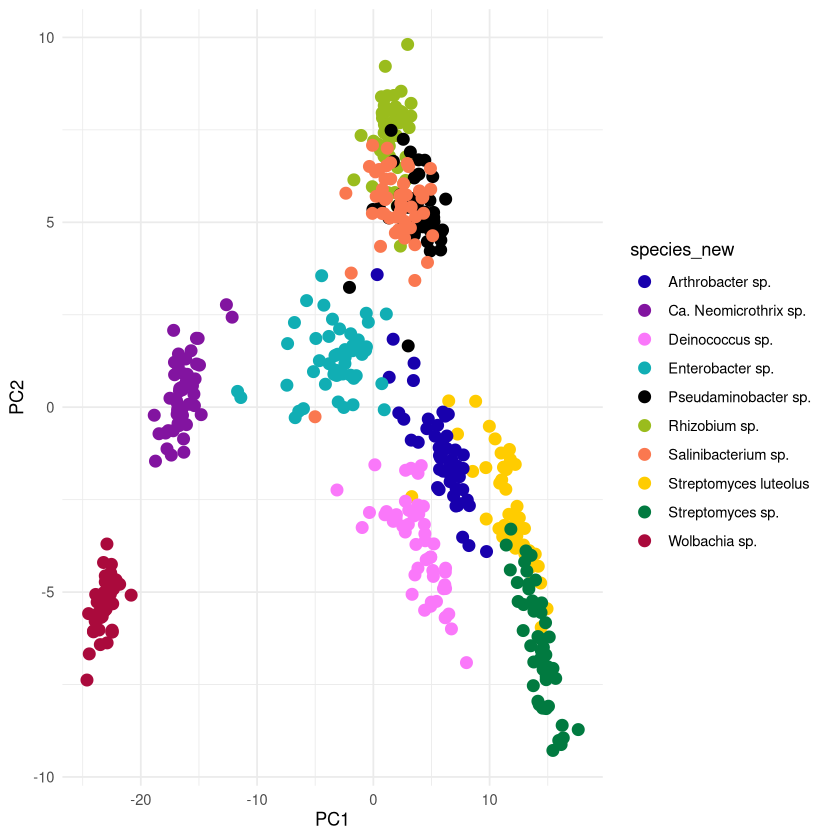

In [9]:
data_tnf <- read.table(tnf_name, header = F, sep=',')
dat_pca_proj_tnf <- create_pca(data_tnf, palette)
dat_pca_proj_tnf$PCA <- "TNF"

## 7. Plot all

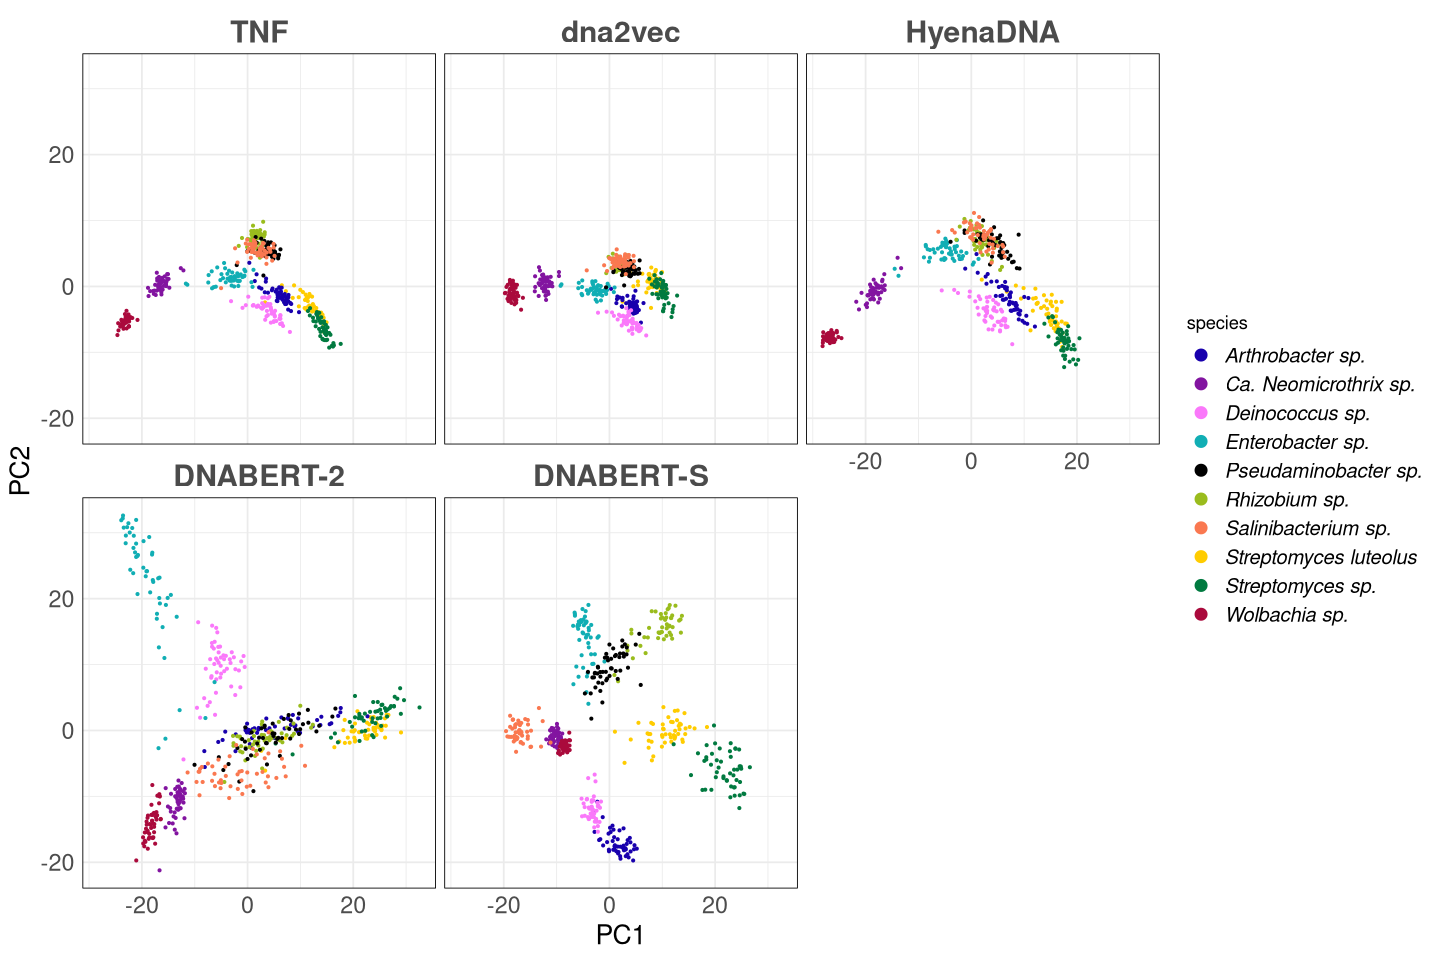

In [10]:
options(repr.plot.width = 12, repr.plot.height = 8)

pca_all <- rbind(dat_pca_proj_dnaberts, dat_pca_proj_hyena, dat_pca_proj_dna2vec, dat_pca_proj_dnabert2, dat_pca_proj_tnf)

pca_all$PCA <- factor(pca_all$PCA, levels = c("TNF", "dna2vec", "HyenaDNA", "DNABERT-2", "DNABERT-S"))

plot_all <- ggplot(pca_all, aes(x = PC1, y = PC2, color = species_new)) +
  geom_point(size = 0.5) +
  facet_wrap(~ PCA, nrow = 2) + 
  labs(x = "PC1", y = "PC2", color = "species") +
  theme_minimal() +
  theme(legend.position = "right", 
        panel.border = element_rect(colour = "black", fill = NA, linewidth = 0.25),
        legend.text = element_text(size = 12, face = "italic"),
        strip.text = element_text(size = 18, face = "bold", colour = "#4b4b4b"),
        axis.text=element_text(size=14),
        axis.title=element_text(size=16)) +
  scale_color_manual(values = palette)+
  guides(color = guide_legend(override.aes = list(size = 3)))

plot_all

In [11]:
ggsave(glue("../../Results/Plots/{dataset_name}_pca_facets_legend_figure_2.png"), plot_all, 
       width = 10, height = 6, dpi = 500)

## 8. Silhouette score on PCA projections

In [12]:
silhouette_scores <- pca_all %>%
  group_by(PCA) %>%
  do({
    coords <- as.matrix(select(., PC1, PC2))
    clusters <- as.factor(.$species)
    
    dist_mat <- dist(coords)
    
    sil <- silhouette(as.numeric(clusters), dist_mat)

    data.frame(mean_silhouette = mean(sil[, 3]), median_silhouette = median(sil[, 3]), sd_silhouette = sd(sil[, 3]))
  }) %>%
  ungroup()

In [13]:
silhouette_scores

PCA,mean_silhouette,median_silhouette,sd_silhouette
<fct>,<dbl>,<dbl>,<dbl>
TNF,0.3778390,0.4565628,0.3703521
dna2vec,0.3114502,0.3634384,0.3575270
HyenaDNA,0.3108363,0.3396468,0.3987431
DNABERT-2,0.1804879,0.2114729,0.3898572
DNABERT-S,0.5100127,0.6083749,0.2825214


## 9. Silhouette score on representations

In [14]:
compute_silhouette_stats <- function(data) {
  coords <- as.matrix(dplyr::select(data, -V1, -V2))
  clusters <- as.factor(data$V2)
  
  dist_mat <- dist(coords)
  sil <- cluster::silhouette(as.numeric(clusters), dist_mat)
  
  data.frame(
    mean_silhouette   = mean(sil[, 3]),
    median_silhouette = median(sil[, 3]),
    sd_silhouette     = sd(sil[, 3])
  )
}

In [15]:
silhouette_scores_dnaberts <- compute_silhouette_stats(data_dnaberts)
print('DNABERT-S:')
silhouette_scores_dnaberts

silhouette_scores_dnabert2 <- compute_silhouette_stats(data_dnabert2)
print('DNABERT-2:')
silhouette_scores_dnabert2

silhouette_scores_hyena <- compute_silhouette_stats(data_hyena)
print('HyenaDNA:')
silhouette_scores_hyena

silhouette_scores_dna2vec <- compute_silhouette_stats(data_dna2vec)
print('dna2vec:')
silhouette_scores_dna2vec

silhouette_scores_bag4mers <- compute_silhouette_stats(data_tnf)
print('TNF:')
silhouette_scores_bag4mers

[1] "DNABERT-S:"


mean_silhouette,median_silhouette,sd_silhouette
<dbl>,<dbl>,<dbl>
0.4384949,0.4554682,0.1291744


[1] "DNABERT-2:"


mean_silhouette,median_silhouette,sd_silhouette
<dbl>,<dbl>,<dbl>
0.205064,0.2342245,0.1998889


[1] "HyenaDNA:"


mean_silhouette,median_silhouette,sd_silhouette
<dbl>,<dbl>,<dbl>
0.2685603,0.2673545,0.2825672


[1] "dna2vec:"


mean_silhouette,median_silhouette,sd_silhouette
<dbl>,<dbl>,<dbl>
0.2844483,0.2724375,0.2216289


[1] "TNF:"


mean_silhouette,median_silhouette,sd_silhouette
<dbl>,<dbl>,<dbl>
0.2355732,0.2446988,0.1454053


## 10. Distance between mean point of all points and mean points of species

In [16]:
mean_species_centroid_distance <- function(df) {
  
  embeddings <- df[, -(1:2)]
  species <- df$V2
  
  data <- data.frame(species, embeddings)
  
  species_centroids <- data %>%
    group_by(species) %>%
    summarise(across(everything(), mean))
  
  global_centroid <- colMeans(embeddings)
  
  distances <- apply(species_centroids[,-1], 1, function(x) {
    sqrt(sum((x - global_centroid)^2))
  })
  
  mean(distances)
}

In [17]:
res <- data.frame(
  model = c("DNABERT-S", "HyenaDNA", "dna2vec", "DNABERT-2", "TNF"),
  mean_distance = c(
    mean_species_centroid_distance(data_dnaberts),
    mean_species_centroid_distance(data_hyena),
    mean_species_centroid_distance(data_dna2vec),
    mean_species_centroid_distance(data_dnabert2),
    mean_species_centroid_distance(data_tnf)
  )
)

res

model,mean_distance
<chr>,<dbl>
DNABERT-S,2.40891544
HyenaDNA,1.52872600
dna2vec,0.24038467
DNABERT-2,1.51324543
TNF,0.03052074
